# Visualizing proportions

**Worksheet · Data 110 · Fall 2026 · Week 10**
Rebin Muhammad

This is the worksheet for the lecture. Do it in class, after the slides. Run each cell with **Shift+Enter**, from the top.

Under each exercise there is an empty cell. Write your solution in that cell, then run it. This file does not contain the answers.

## How to open this in Google Colab

1. Go to [colab.research.google.com](https://colab.research.google.com).
2. Choose **File → Upload notebook** and select this file.
3. Upload `bundestag.csv`, `marketshare.csv`, and `rwanda.csv` before you run the data cells. Click the **folder icon** on the left, then the **upload icon**. The names must stay the same. Colab forgets uploaded files when the session ends, so you upload them again next time.


## Setup

pandas holds the tables. matplotlib draws the charts. numpy holds the positions of the grouped bars.


In [1]:
import matplotlib.pyplot as plt  # pyplot draws the plots. We call it plt.
import numpy as np                # numpy holds the year positions. We call it np.
import pandas as pd               # pandas holds tables. We call it pd.

# The spines are the four lines that make the frame.
# False hides the top line and the right line.
plt.rcParams["axes.spines.top"] = False
plt.rcParams["axes.spines.right"] = False


## The parliament

One row is one party in the 8th German Bundestag, 1976–1980.

- `party` is CDU/CSU, SPD, or FDP.
- `seats` is the number of seats. The three numbers add to 496.

`read_csv` turns the file into a table.


In [2]:
bundestag = pd.read_csv("bundestag.csv")
bundestag


,party,seats
0,CDU/CSU,243
1,SPD,214
2,FDP,39


## A color for each party

A dictionary pairs each party with one color. Blue is CDU/CSU, gold is SPD, and green is FDP. The colors name the parties. They are not a measure of the seats.


In [3]:
party_colors = {"CDU/CSU": "#0072B2", "SPD": "#E69F00", "FDP": "#009E73"}


## 1. A pie

**Exercise.** Draw a pie of `bundestag["seats"]`. Use the party names as the labels, and use `party_colors` for the slices.

`pie` draws one slice per number. The circle is the sum of the seats. `startangle=90` starts the first slice at the top. Build the color list with `[party_colors[name] for name in bundestag["party"]]`.

### Your solution

Write your code in the next cell, then run it.


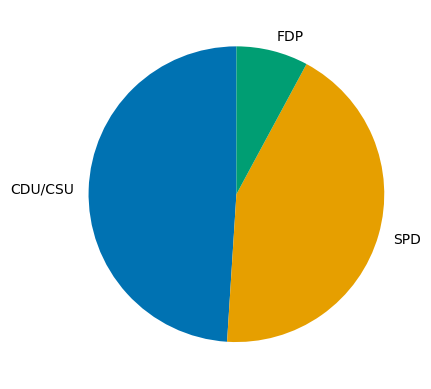

In [12]:
# Write your solution here.
color = [party_colors[name] for name in bundestag["party"]]

plt.pie(bundestag["seats"], labels = bundestag["party"], startangle = 90, colors = color)
plt.show()

## 2. Side-by-side bars

**Exercise.** Draw one bar per party. Put `party` on the horizontal axis and `seats` on the vertical axis. Use `party_colors` again. Label the vertical axis `seats`.

Both bars for the large parties start at zero, so 243 and 214 are easy to compare.

### Your solution

Write your code in the next cell, then run it.


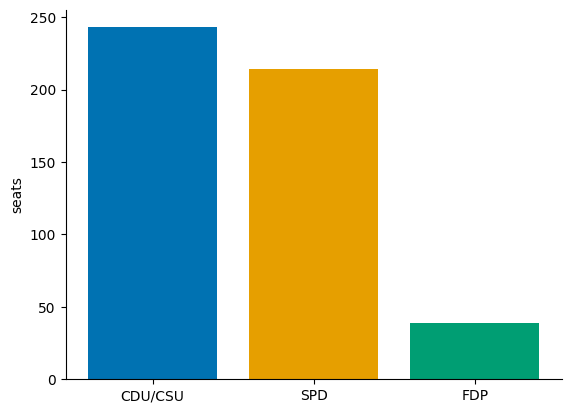

In [16]:
# Write your solution here.
plt.bar(bundestag["party"], bundestag["seats"], color = color)
plt.ylabel("seats")
plt.show()

## 3. The percent

**Exercise.** Add a column named `percent`. Divide `seats` by the sum of `seats`, multiply by 100, and keep one decimal place. Then show the table.

`sum` adds the column. `round(1)` keeps one decimal place. CDU/CSU should be 49.0, SPD 43.1, and FDP 7.9.

### Your solution

Write your code in the next cell, then run it.


In [27]:
# Write your solution here.
seat_sum = bundestag["seats"].sum() # 496

bundestag["percent"] = ((bundestag["seats"] / seat_sum) * 100).round(1)
bundestag # correct percents!

,party,seats,percent
0,CDU/CSU,243,49.0
1,SPD,214,43.1
2,FDP,39,7.9


## The companies

One row is one company in one year. The shares are made up.

- `company` is A, B, C, D, or E.
- `year` is 2015, 2016, or 2017.
- `percent` is that company's share of the market. In each year the five percents add to 100.

Blue is A, sky blue is B, green is C, gold is D, and vermillion is E.


In [26]:
share = pd.read_csv("marketshare.csv")
company_colors = {
    "A": "#0072B2",
    "B": "#56B4E9",
    "C": "#009E73",
    "D": "#E69F00",
    "E": "#D55E00",
}
share.head()


,percent,company,year
0,17,A,2015
1,18,B,2015
2,20,C,2015
3,22,D,2015
4,23,E,2015


## 4. Five bars beside each year

**Exercise.** Draw the market shares as side-by-side bars. Each year has five bars, one per company, and every bar starts at zero.

`np.arange(3)` is the position of 2015, 2016, and 2017. `width = 0.15` is the width of one bar. `enumerate` walks through the companies and counts them: `i` is 0, 1, 2, 3, 4. The shift `(i - 2) * width` is −2, −1, 0, 1, 2 bar-widths, so the five bars sit beside each other instead of on top of the same spot.

Sort each company by `year` before you plot it, so 2015 is the first bar. Label the vertical axis `market share (%)`, and add a legend.

### Your solution

Write your code in the next cell, then run it.


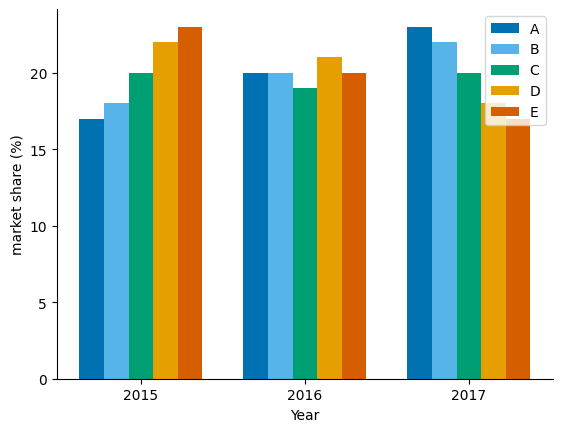

In [36]:
# Write your solution here.
x_indexes = np.arange(3)
width = 0.15

companies = ["A", "B", "C", "D", "E"]

for i, company in enumerate(companies):
  company_data = share.loc[share["company"] == company].sort_values("year")
  plt.bar(x_indexes + (i - 2) * width, company_data["percent"], width = width, label = company, color = company_colors[company])


plt.xticks(ticks = x_indexes, labels = [2015,2016,2017])

plt.xlabel("Year")
plt.ylabel("market share (%)")
plt.legend()
plt.show()


## Rwanda

One row is one year of the Rwandan parliament, from 1997 to 2016.

- `year` is the year.
- `women` is the percent of seats held by women.
- `men` is the percent held by men. The two columns add to 100.

The percentage stays the same for several years, then jumps.


In [33]:
rwanda = pd.read_csv("rwanda.csv")
rwanda.head()


,year,women,men
0,1997,17.1,82.9
1,1998,17.1,82.9
2,1999,17.1,82.9
3,2000,25.7,74.3
4,2001,25.7,74.3


## 5. Stack women and men

**Exercise.** Draw a stacked bar for each year. Women are on the bottom, in `#D55E00`. Men are on top, in `#0072B2`. Draw a dashed line at 50.

`bottom=rwanda["women"]` starts the men at the top of the women bar. `axhline` draws a horizontal line; `linestyle="--"` makes it dashed. Label the vertical axis `share of seats (%)`, and add a legend.

The line at 50 is half the parliament. Women first rise above it in 2008.

### Your solution

Write your code in the next cell, then run it.


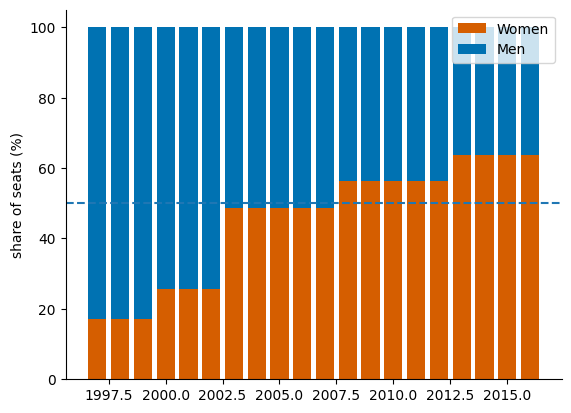

In [37]:
# Write your solution here.

plt.bar(rwanda["year"], rwanda["women"], color = "#D55E00", label = "Women")
plt.bar(rwanda["year"], rwanda["men"], bottom = rwanda["women"], color = "#0072B2", label = "Men")

plt.axhline(y = 50, linestyle = "--")

plt.ylabel("share of seats (%)")
plt.legend()
plt.show()